#  Metadata-only shortcut test on APTOS-2019

**Question.** Can the DR grade be predicted from image *metadata alone* (resolution, framing, colour and sharpness statistics), without looking at any retinal structure?

**Why it matters.** If it can, a CNN could reach good scores through the same cues instead of through lesions. This notebook measures how large that risk is *before* training any CNN. It does not prove that a CNN uses these cues.

**Design**

| | |
|---|---|
| **Models** | Two deliberately simple families: L2 logistic regression (linear, transparent) and shallow histogram gradient boosting (can pick up thresholds and interactions). |
| **Features** | 13 whole-image measurements first (to compare with the earlier run), then feature groups in Section 5. |
| **Selection** | 5-fold `StratifiedGroupKFold` on the **train** partition. Near-duplicate images share a fold. All preprocessing (log, percentile caps, imputation, scaling) is fitted inside each fold. |
| **Evaluation** | The **validation** partition is used once for the locked model. The sealed **test** partition is not touched. |
| **Metrics** | Quadratic weighted kappa (QWK, primary: grades are ordered), macro-F1 and balanced accuracy. Baselines: majority class and stratified random guessing. |

**Prerequisite.** Run `01_image_variation.ipynb` first (it creates `data/processed/aptos_development_image_metadata.csv`).

**Reading guide.** Each section is: *what we do → code → observation → interpretation*. Numbers quoted in text are from the run of 28 Oct 2026 (seed 42) and from the saved metadata CSV. Check them against your printed output after any re-run; gradient boosting can move the third decimal.

# 0 Setup

In [11]:
from itertools import product
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score, classification_report, cohen_kappa_score, confusion_matrix,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict

sns.set_theme(style="whitegrid", context="notebook")

# Check for project directory
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "fundus").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent


if not (PROJECT_ROOT / "src" / "fundus").is_dir():
    raise FileNotFoundError("Could not find src/fundus; run from the project root or the notebooks/ folder.")

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))


# Import from src/fundus
from fundus.duplicates import build_duplicate_groups
from fundus.features.shortcut import (
    ACQUISITION_FEATURES, ALL_WHOLE_IMAGE_FEATURES, FOV_COLOUR_SHARPNESS_FEATURES, FOV_FRAMING_FEATURES,
    GRADE_LABELS, GRADE_NAMES, WHOLE_IMAGE_FEATURES, cross_validate_pipeline, make_shortcut_pipeline,
    resolution_label, resolution_lookup_predictions, shortcut_metrics,
)



SEED = 42

# Split data (train/test/val)
SPLIT_CSV = PROJECT_ROOT / "configs" / "splits" / "aptos_v1.csv"

# Image metadata and duplicates 
METADATA_CSV = PROJECT_ROOT / "data" / "processed" / "aptos_development_image_metadata.csv"
DUPLICATE_CSV = PROJECT_ROOT / "data" / "processed" / "aptos_development_duplicate_groups.csv"

# Import reports 
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def rel(path):
    try:
        return str(Path(path).resolve().relative_to(PROJECT_ROOT))
    except ValueError:
        return Path(path).name

print("Split manifest:   ", rel(SPLIT_CSV))
print("Metadata output:  ", rel(METADATA_CSV))
print("Figure directory: ", rel(FIGURE_DIR))

Split manifest:    configs/splits/aptos_v1.csv
Metadata output:   data/processed/aptos_development_image_metadata.csv
Figure directory:  reports/figures


# 1 Load the development data

Only metadata and the split manifest are read. The split column comes from the manifest (authoritative), and test rows are dropped immediately.

In [27]:
# MetaData
metadata = pd.read_csv(METADATA_CSV).drop(columns=["split"], errors="ignore")

# Split data (train/test/val)
manifest = pd.read_csv(SPLIT_CSV, usecols=["id_code", "diagnosis", "split"])

# Make id code as string 
manifest["id_code"] = manifest["id_code"].astype(str)


# Merge both datasets 
model_data = (
    metadata.merge(manifest, left_on="image_id", right_on="id_code", validate="one_to_one")
    .drop(columns="id_code")
)

# Extract only training and validation data 
model_data = model_data[model_data["split"].isin(["train", "val"])].reset_index(drop=True)

# Add resolution of each image 
model_data["resolution"] = resolution_label(model_data)


# Splitting into Training and validation sets 
train_data = model_data[model_data["split"] == "train"].reset_index(drop=True)
val_data = model_data[model_data["split"] == "val"].reset_index(drop=True)


SHORTCUT_FEATURES = ALL_WHOLE_IMAGE_FEATURES            # The 13 whole-image measurements
FOV_AVAILABLE = all(c in model_data for c in FOV_FRAMING_FEATURES + FOV_COLOUR_SHARPNESS_FEATURES)

# Extract labels/diagnosis for train and validation 
y_train = train_data["diagnosis"].astype(int).to_numpy()
y_val = val_data["diagnosis"].astype(int).to_numpy()

# Extract the features 
X_train, X_val = train_data[SHORTCUT_FEATURES].astype(float) , val_data[SHORTCUT_FEATURES].astype(float)


# Check for missing values 
assert not X_train.isna().any().any() and not X_val.isna().any().any(), "Unexpected missing metadata"

# Check for labels 
assert set(y_train) == set(GRADE_LABELS) and set(y_val) == set(GRADE_LABELS), "Expected all 5 grades in train and validation"

# Check for duplicate images 
assert not set(train_data["image_id"]) & set(val_data["image_id"]), "Image ID leakage between train and validation"

print("---- ImageData Loaded ---- ")
print(f"Train: {len(train_data):,}   validation: {len(val_data):,}   test: not loaded")
print("Train grade counts:     ", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Validation grade counts:", pd.Series(y_val).value_counts().sort_index().to_dict())
print("FOV measurements available:", FOV_AVAILABLE)



---- ImageData Loaded ---- 
Train: 2,438   validation: 525   test: not loaded
Train grade counts:      {0: 1256, 1: 236, 2: 645, 3: 117, 4: 184}
Validation grade counts: {0: 270, 1: 51, 2: 138, 3: 26, 4: 40}
FOV measurements available: True


In [26]:
X_val

,width,height,aspect_ratio,file_size_bytes,brightness_mean,red_mean,green_mean,blue_mean,red_std,green_std,blue_std,blur_laplacian_variance,black_border_fraction
0,3216.0,2136.0,1.505618,3218676.0,51.388750,80.742828,43.169880,16.429441,49.583111,26.907301,9.372180,6.258779,0.253113
1,2048.0,1536.0,1.333333,1819430.0,22.645921,38.465210,18.830799,0.795823,43.880562,22.661142,4.080910,27.614819,0.525066
2,3388.0,2588.0,1.309119,7401201.0,66.397845,93.385330,61.553558,20.410582,54.093765,35.378063,11.962368,13.837247,0.244210
3,2588.0,1958.0,1.321757,5223375.0,49.541231,55.733955,46.763756,47.475842,22.144121,15.605129,12.617947,12.599714,0.000008
4,3216.0,2136.0,1.505618,2515726.0,74.169263,125.690666,60.054893,11.159502,73.618225,36.040634,6.203192,4.035059,0.252289
...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,2588.0,1958.0,1.321757,5780020.0,71.013600,85.606956,66.222366,57.465527,40.499981,28.890404,23.594820,16.471686,0.091552
521,2416.0,1736.0,1.391705,1976889.0,52.439548,96.102417,39.120136,6.279682,47.223415,18.693417,3.324975,9.095153,0.166255
522,1050.0,1050.0,1.000000,1005004.0,85.709325,137.757950,70.277039,28.641296,72.745117,38.470711,20.720808,48.442576,0.200932
523,2416.0,1736.0,1.391705,2333015.0,69.554928,113.772667,58.185539,11.731994,53.857704,28.852816,5.474798,10.574295,0.165590


## 2 · Near-duplicate images

APTOS has no patient IDs, so we cannot keep one person's photographs together. What we *can* do is keep **copies of the same photograph** together. Two images are linked when their perceptual hashes differ by at most 4 bits **and** the structural similarity (SSIM) of their 128 × 128 versions is at least 0.95; links are merged transitively into groups.

The earlier version of this analysis searched for duplicates among **training images only**. That protects the cross-validation folds, but it cannot show whether a validation image has a near-twin in training, which would make the validation score look better than it is. Here the search covers *all development images* so both questions can be answered. The result is cached, because comparing ~3,000 images takes a while.

In [29]:

# Making or loading duplicate images 
def load_or_build_duplicate_groups():
    
    if DUPLICATE_CSV.exists():
        cached = pd.read_csv(DUPLICATE_CSV)
        if set(cached["image_id"]) == set(model_data["image_id"]):
            return cached.set_index("image_id")["group_id"].reindex(model_data["image_id"]).to_numpy(), "loaded from cache"
    
    started = time.perf_counter()
    group_ids, links = build_duplicate_groups(model_data["image_path"].tolist())
    pd.DataFrame({"image_id": model_data["image_id"], "group_id": group_ids}).to_csv(DUPLICATE_CSV, index=False)
    
    return group_ids, f"computed in {time.perf_counter() - started:.0f}s ({len(links)} links)"

group_ids, source_note = load_or_build_duplicate_groups()
model_data["group_id"] = group_ids

group_sizes = model_data.groupby("group_id")["image_id"].transform("size")
groups_spanning_splits = model_data.groupby("group_id")["split"].nunique()


cross_split_groups = groups_spanning_splits[groups_spanning_splits > 1].index
val_with_twin_in_train = model_data[(model_data["split"] == "val") & model_data["group_id"].isin(cross_split_groups)]


print(f"Duplicate groups: {model_data['group_id'].nunique():,} groups for {len(model_data):,} images ({source_note})")
print(f"Images in a group of 2 or more: {int((group_sizes > 1).sum())}")
print(f"Groups that span train AND validation: {len(cross_split_groups)}  -> validation images affected: {len(val_with_twin_in_train)}")


if len(val_with_twin_in_train):
    print("WARNING: validation images with a near-duplicate in training exist; a clean-validation check is run in Section 4.")

Duplicate groups: 2,961 groups for 2,963 images (loaded from cache)
Images in a group of 2 or more: 4
Groups that span train AND validation: 0  -> validation images affected: 0


In [30]:
# Group labels for the training rows, used to keep near-duplicates in the same CV fold.
cv_groups = train_data[["image_id"]].merge(model_data[["image_id", "group_id"]], on="image_id", how="left")["group_id"].to_numpy()

# Cross validation split 
cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv_splitter.split(X_train, y_train, groups=cv_groups))


for fold_number, (fit_indices, score_indices) in enumerate(cv_splits, start=1):
    
    if set(cv_groups[fit_indices]) & set(cv_groups[score_indices]):
        raise AssertionError(f"A duplicate group crosses CV fold {fold_number}")

print("5 folds; no duplicate group crosses a fold boundary.")
print("Rows per fold:", [len(score) for _, score in cv_splits])

5 folds; no duplicate group crosses a fold boundary.
Rows per fold: [488, 488, 487, 487, 488]


**Observation.** 

The first analysis found 2 near-duplicate links among 2,438 training images (2,436 groups). The cell above reports the same check across the whole development set and counts how many groups span train and validation.

**Interpretation.** 

- Very few exact or near-exact copies exist, so grouped folds change little, but the check is cheap insurance. 

- The SSIM/hash rule only finds copies that are nearly identical, the same photograph cropped, rotated or recoloured would be missed. This is image-grouped, not patient-level, validation. 

- Rows per fold are close to equal, so fold scores are comparable. **If the "span train AND validation" count is not zero**, the clean-validation check in Section 4 shows how much it matters.

# 3  Model selection with grouped cross-validation (13 whole-image features)

We compare 12 pre-declared configurations (4 logistic regressions and 8 gradient-boosting variants) plus two dummy baselines. The best configuration by **mean cross-validated QWK on training data** is locked *before* looking at validation.

In [40]:
candidates = []
# C_value is a hyperparameter that controls the inverse of the regularization strength.
# It determines the trade-off between fitting the training data closely and keeping the model coefficients small to prevent overfitting.

# ===================================
# LOGISTIC REGRESSION 
# ===================================

c = [0.01, 0.1, 1.0, 10.0]
for c_value in c:
    candidates.append((
        f"LogisticRegression C={c_value}",
        LogisticRegression(C=c_value, class_weight="balanced", max_iter=2000, random_state=SEED),
    ))


# ===================================
# HIST GRADIENT BOOSTING 
# ===================================


# Hyper parameters
max_leaf = [10, 50]
lr = [0.05, 0.1]
max_itr = [100, 200]


for max_leaf_nodes, learning_rate, max_iter in product(max_leaf, lr ,max_itr ):
    
    candidates.append((
        f"HistGradientBoosting leaves={max_leaf_nodes}, lr={learning_rate}, iter={max_iter}",
        HistGradientBoostingClassifier(
            max_leaf_nodes=max_leaf_nodes, learning_rate=learning_rate, max_iter=max_iter,
            min_samples_leaf=20, l2_regularization=1.0, class_weight="balanced",
            early_stopping=False, random_state=SEED,
        ),
    ))

# ==================================
# BASELINE CLASSIFICATION 
# ==================================


baselines = [
    ("Dummy: most_frequent", DummyClassifier(strategy="most_frequent")),
    ("Dummy: stratified", DummyClassifier(strategy="stratified", random_state=SEED)),
]


print(f"{len(candidates)} candidate configurations + {len(baselines)} dummy baselines")

12 candidate configurations + 2 dummy baselines


In [41]:

# Evaluation Metrics 
METRICS = ["qwk", "macro_f1", "balanced_accuracy", "accuracy"]


def summarise(name, fold_table):
    
    row = {"model": name}
    for metric in METRICS:
        row[f"{metric}_mean"] = fold_table[metric].mean()
        row[f"{metric}_std"] = fold_table[metric].std(ddof=1)
        
    return row



started = time.perf_counter()
fold_tables, summary_rows = {}, []

# Fit on train with all three models 
for name, classifier in candidates + baselines:
    
    fold_table = cross_validate_pipeline(make_shortcut_pipeline(classifier, SHORTCUT_FEATURES), X_train, y_train, cv_splits)
    fold_tables[name] = fold_table.assign(model=name)
    
    summary_rows.append(summarise(name, fold_table))

cv_search_seconds = time.perf_counter() - started

# Evaluation Summary
cv_all = pd.DataFrame(summary_rows)
is_baseline = cv_all["model"].str.startswith("Dummy")
cv_summary = cv_all[~is_baseline].sort_values("qwk_mean", ascending=False).reset_index(drop=True)
baseline_cv = cv_all[is_baseline].reset_index(drop=True)


print(f"{len(candidates)} configurations x 5 folds + baselines in {cv_search_seconds:.0f}s")
display(cv_summary.round(3))
display(baseline_cv.round(3))

12 configurations x 5 folds + baselines in 92s


,model,qwk_mean,qwk_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std
0,"HistGradientBoosting leaves=50, lr=0.1, iter=200",0.713,0.014,0.467,0.035,0.461,0.029,0.715,0.019
1,"HistGradientBoosting leaves=50, lr=0.1, iter=100",0.710,0.013,0.470,0.031,0.465,0.025,0.714,0.015
2,"HistGradientBoosting leaves=10, lr=0.1, iter=200",0.704,0.027,0.483,0.016,0.481,0.016,0.717,0.014
3,"HistGradientBoosting leaves=50, lr=0.05, iter=200",0.701,0.022,0.465,0.033,0.461,0.028,0.712,0.020
4,"HistGradientBoosting leaves=10, lr=0.05, iter=200",0.695,0.012,0.484,0.022,0.492,0.023,0.702,0.014
5,"HistGradientBoosting leaves=50, lr=0.05, iter=100",0.691,0.020,0.470,0.025,0.467,0.023,0.710,0.013
6,"HistGradientBoosting leaves=10, lr=0.1, iter=100",0.686,0.019,0.475,0.025,0.482,0.025,0.701,0.020
7,"HistGradientBoosting leaves=10, lr=0.05, iter=100",0.685,0.010,0.480,0.022,0.496,0.024,0.693,0.016
8,LogisticRegression C=1.0,0.642,0.024,0.413,0.028,0.460,0.027,0.621,0.016
9,LogisticRegression C=10.0,0.641,0.017,0.415,0.021,0.462,0.016,0.624,0.012


,model,qwk_mean,qwk_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std
0,Dummy: most_frequent,0.000,0.000,0.136,0.000,0.20,0.000,0.515,0.001
1,Dummy: stratified,0.015,0.033,0.210,0.026,0.21,0.025,0.366,0.017


In [ ]:
# Best Model 

# After Running this combinations of  Hyper parameters
# max_leaf = [7, 15, 20, 50]
# lr = [0.05, 0.1, 0.01, 0.001]
# max_itr = [100, 200, 500]

cv_summary.iloc[0]

model                     HistGradientBoosting leaves=50, lr=0.1, iter=200
qwk_mean                                                          0.713357
qwk_std                                                           0.014428
macro_f1_mean                                                     0.466743
macro_f1_std                                                      0.034737
balanced_accuracy_mean                                            0.461293
balanced_accuracy_std                                              0.02882
accuracy_mean                                                     0.714935
accuracy_std                                                      0.018662
Name: 0, dtype: object

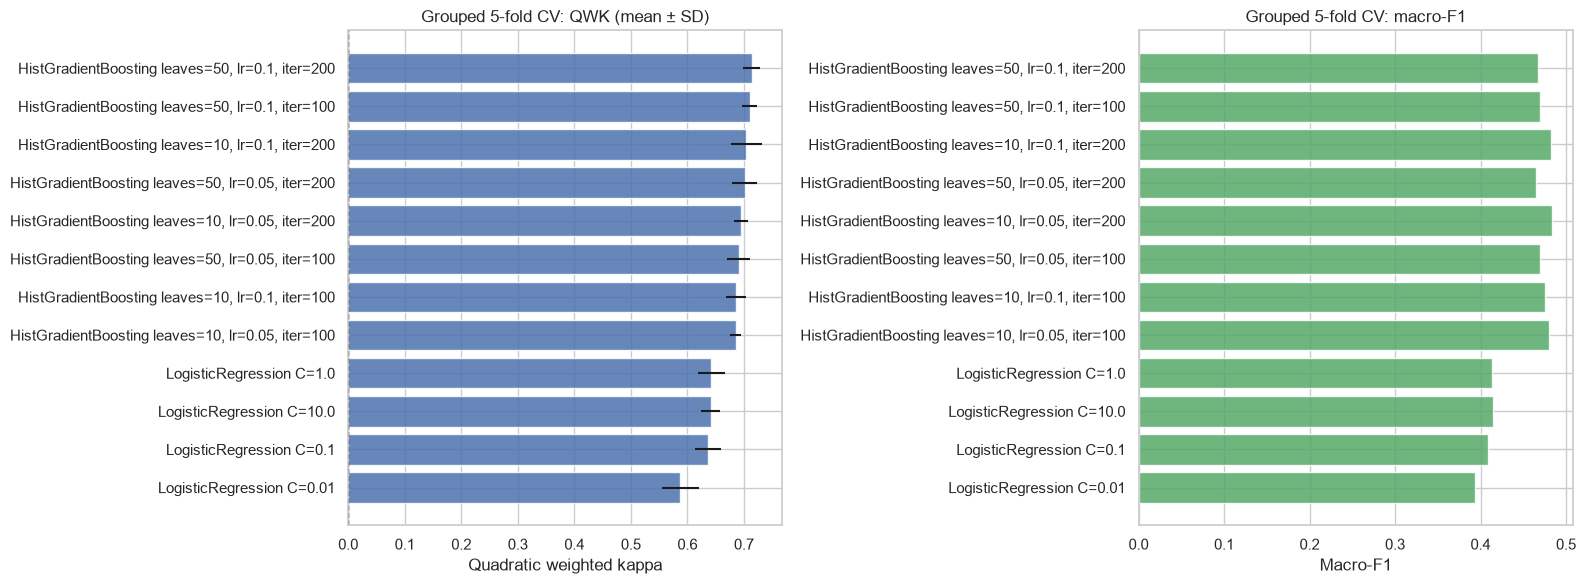

In [44]:

# Best Model : HistGradient 
best_cv_row = cv_summary.iloc[0] 
best_model_name = best_cv_row["model"]
locked_classifier = dict(candidates)[best_model_name]

# Save the result to report 
cv_summary.to_csv(REPORT_DIR / "aptos_metadata_shortcut_cv.csv", index=False)
pd.concat(fold_tables.values()).to_csv(REPORT_DIR / "aptos_metadata_shortcut_cv_folds.csv", index=False)

plot_summary = cv_summary.sort_values("qwk_mean")



fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(plot_summary["model"], plot_summary["qwk_mean"], xerr=plot_summary["qwk_std"].fillna(0), color="#4C72B0", alpha=0.85)
axes[0].axvline(0, color="black", lw=1, ls="--")
axes[0].set(title="Grouped 5-fold CV: QWK (mean ± SD)", xlabel="Quadratic weighted kappa")
axes[1].barh(plot_summary["model"], plot_summary["macro_f1_mean"], color="#55A868", alpha=0.85)
axes[1].set(title="Grouped 5-fold CV: macro-F1", xlabel="Macro-F1")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "aptos_metadata_shortcut_cv.png", dpi=160, bbox_inches="tight")
plt.show()



In [45]:
print("Locked using training CV only:", best_model_name)
print(f"CV QWK = {best_cv_row['qwk_mean']:.3f} ± {best_cv_row['qwk_std']:.3f};  macro-F1 = {best_cv_row['macro_f1_mean']:.3f};  "
    f"balanced accuracy = {best_cv_row['balanced_accuracy_mean']:.3f}")

Locked using training CV only: HistGradientBoosting leaves=50, lr=0.1, iter=200
CV QWK = 0.713 ± 0.014;  macro-F1 = 0.467;  balanced accuracy = 0.461


In [46]:
cv_summary.iloc[0]

model                     HistGradientBoosting leaves=50, lr=0.1, iter=200
qwk_mean                                                          0.713357
qwk_std                                                           0.014428
macro_f1_mean                                                     0.466743
macro_f1_std                                                      0.034737
balanced_accuracy_mean                                            0.461293
balanced_accuracy_std                                              0.02882
accuracy_mean                                                     0.714935
accuracy_std                                                      0.018662
Name: 0, dtype: object

**Observations.** 

- All eight gradient-boosting configurations beat all four logistic regressions. The best is `HistGradientBoosting leaves = 50, lr= 0.1, iter=200` with mean CV QWK 0.7133 (SD 0.014), macro-F1 0.468, balanced accuracy 0.461. 

- The best logistic regression (C=1.0) reaches QWK 0.642. 

- The dummy baselines score QWK 0.000 (most frequent) and −0.044 (stratified). The spread between the eight boosting settings is small (QWK 0.672 to 0.698), comparable to one or two fold standard deviations.

**Interpretation.** 

- Metadata alone is far above chance (QWK 0 means no better than guessing; the model is at ~0.70). A linear model already captures most of it (0.64), and trees add a little more by exploiting thresholds, which fits the picture of discrete image sources with different case mixes. Because the top configurations differ by less than the fold noise, the exact choice of hyperparameters does not matter.

- The conclusion does not depend on it. Macro-F1 and balanced accuracy (~0.47) are much lower than QWK suggests, because the rare grades are poorly predicted (next section).

# 4  One evaluation on the validation partition

The locked model is fitted on all training rows and evaluated once on validation, next to the two baselines.

In [55]:

locked_pipeline = make_shortcut_pipeline(clone(locked_classifier), SHORTCUT_FEATURES).fit(X_train, y_train)
y_val_pred = locked_pipeline.predict(X_val)
validation_metrics = shortcut_metrics(y_val, y_val_pred)

majority_pred = np.full_like(y_val, pd.Series(y_train).mode().iloc[0])
stratified_pred = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, y_train).predict(X_val)
validation_baselines = {
    "majority": shortcut_metrics(y_val, majority_pred),
    "stratified_random": shortcut_metrics(y_val, stratified_pred),
}
print("Locked model:", best_model_name)
print("Validation:        ", {k: round(v, 3) for k, v in validation_metrics.items()})
for name, values in validation_baselines.items():
    print(f"Baseline {name:18s}", {k: round(v, 3) for k, v in values.items()})

report = classification_report(y_val, y_val_pred, labels=GRADE_LABELS, target_names=[GRADE_NAMES[g] for g in GRADE_LABELS],
                            output_dict=True, zero_division=0)
per_grade = pd.DataFrame(report).T.loc[[GRADE_NAMES[g] for g in GRADE_LABELS], ["precision", "recall", "f1-score", "support"]]
display(per_grade.round(3))



Locked model: HistGradientBoosting leaves=50, lr=0.1, iter=200
Validation:         {'qwk': 0.686, 'macro_f1': 0.442, 'balanced_accuracy': 0.44, 'accuracy': 0.691}
Baseline majority           {'qwk': 0.0, 'macro_f1': 0.136, 'balanced_accuracy': 0.2, 'accuracy': 0.514}
Baseline stratified_random  {'qwk': -0.022, 'macro_f1': 0.199, 'balanced_accuracy': 0.201, 'accuracy': 0.358}


,precision,recall,f1-score,support
No DR,0.923,0.933,0.928,270.0
Mild,0.308,0.235,0.267,51.0
Moderate,0.558,0.623,0.589,138.0
Severe,0.250,0.231,0.240,26.0
Proliferative,0.200,0.175,0.187,40.0


In [56]:
# Sensitivity check: drop validation images that have a near-duplicate twin in the training partition.
clean_mask = ~val_data["image_id"].isin(val_with_twin_in_train["image_id"]).to_numpy()
if clean_mask.all():
    print("No validation image has a near-duplicate in training; the clean-validation check is not needed.")
else:
    clean_metrics = shortcut_metrics(y_val[clean_mask], y_val_pred[clean_mask])
    print(f"Clean validation ({clean_mask.sum()} of {len(y_val)} images):", {k: round(v, 3) for k, v in clean_metrics.items()})

No validation image has a near-duplicate in training; the clean-validation check is not needed.


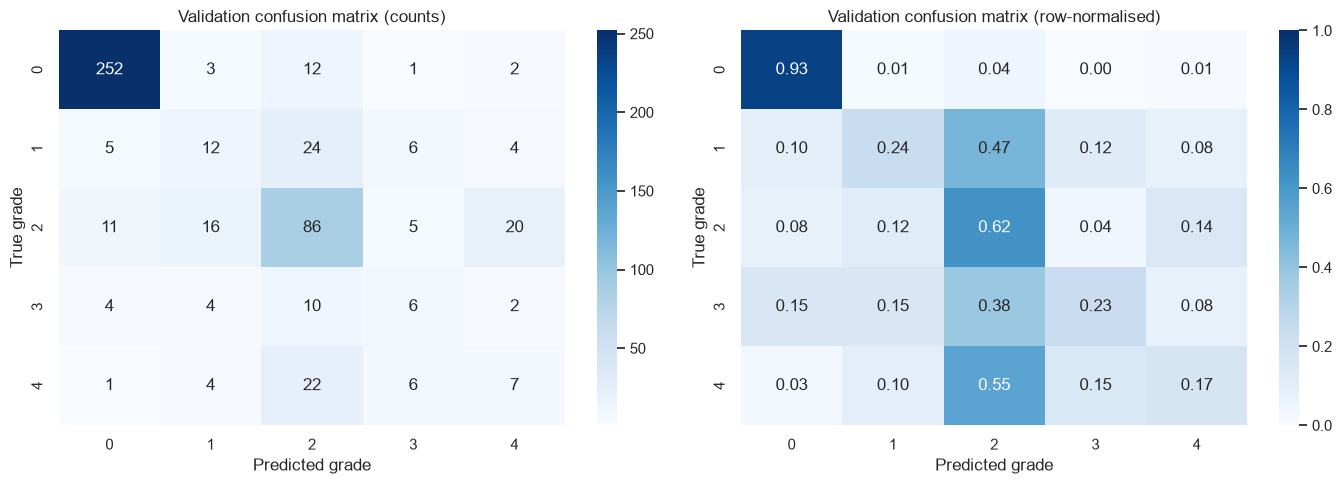

In [ ]:
# Confusion matrix on validation images 
confusion = confusion_matrix(y_val, y_val_pred, labels=GRADE_LABELS)
confusion_normalised = confusion / confusion.sum(axis=1, keepdims=True)\


# For Counts 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", xticklabels=GRADE_LABELS, yticklabels=GRADE_LABELS, ax=axes[0])
axes[0].set(title="Validation confusion matrix (counts)", xlabel="Predicted grade", ylabel="True grade")

# For Normalised
sns.heatmap(confusion_normalised, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=GRADE_LABELS, yticklabels=GRADE_LABELS, ax=axes[1])
axes[1].set(title="Validation confusion matrix (row-normalised)", xlabel="Predicted grade", ylabel="True grade")


fig.tight_layout()
fig.savefig(FIGURE_DIR / "aptos_metadata_shortcut_validation_confusion.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation.** 

- On the 525 validation images the locked model reaches QWK 0.686, macro-F1 0.421, balanced accuracy 0.44 and accuracy 0.691, in line with cross-validation (0.686). 
- The majority baseline has accuracy 0.514, balanced accuracy 0.200 and QWK 0.000. 
- The stratified-random baseline has accuracy 0.358 and QWK −0.022. Per-grade recall: No DR 0.926 (270 images), Moderate 0.580 (138), Mild 0.255 (51), Proliferative 0.225 (40), Severe 0.115 (26).

**Interpretation.** 

- The validation result confirms the cross-validation result, so it is not a fluke of one split. The metadata model separates "No DR" from the rest very well (recall 0.93) and Moderate reasonably, and fails on the rare, severe grades.

- That pattern is what source-recognition would produce: some sources are all healthy, some are mostly Moderate, and the severe grades are scattered across the sources. The validation numbers for Severe (26 images) and Proliferative (40) are very uncertain. If a clean-validation line printed above, compare it with 0.686; a difference of about 0.01–0.02 would be within noise.

## 4.1 Which measurements does the locked model rely on?

Permutation importance on validation: shuffle one measurement at a time and see how much QWK drops (10 shuffles each). This describes the model's reliance, not causation, and it is not another tuning step.

In [ ]:
rng = np.random.default_rng(SEED)
importance_rows = []


for feature in SHORTCUT_FEATURES:
    permuted = X_val.copy()
    original_values = permuted[feature].to_numpy(copy=True)
    drops = []
    
    for _ in range(10):
        permuted[feature] = rng.permutation(original_values)
        drops.append(validation_metrics["qwk"] - shortcut_metrics(y_val, locked_pipeline.predict(permuted))["qwk"])
    importance_rows.append({"feature": feature, "mean_qwk_drop": np.mean(drops), "std_qwk_drop": np.std(drops, ddof=1)})


importance = pd.DataFrame(importance_rows).sort_values("mean_qwk_drop", ascending=False).reset_index(drop=True)
importance.to_csv(REPORT_DIR / "aptos_metadata_shortcut_permutation_importance.csv", index=False)
display(importance.round(4))



,feature,mean_qwk_drop,std_qwk_drop
0,aspect_ratio,0.1688,0.0248
1,black_border_fraction,0.0544,0.0181
2,file_size_bytes,0.0481,0.0145
3,width,0.0449,0.0130
4,blue_mean,0.0367,0.0120
5,blue_std,0.0328,0.0175
6,green_std,0.0234,0.0122
7,red_std,0.0231,0.0147
8,red_mean,0.0167,0.0093
9,brightness_mean,0.0141,0.0117


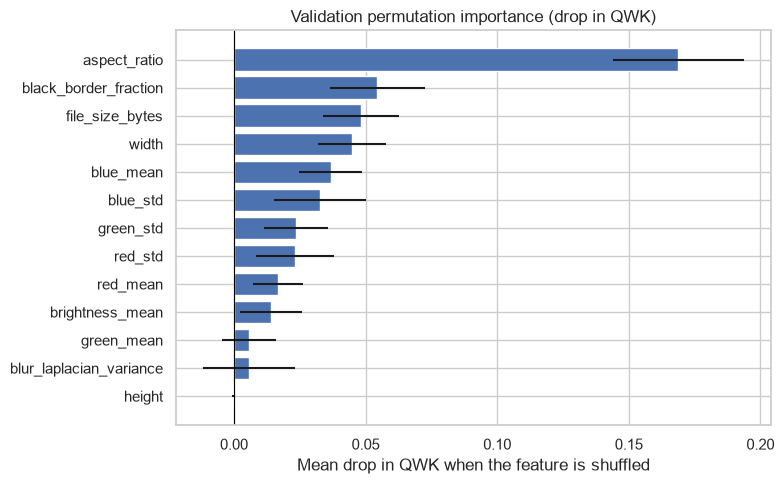

In [59]:
plt.figure(figsize=(8, 5))
plt.barh(importance["feature"][::-1], importance["mean_qwk_drop"][::-1], xerr=importance["std_qwk_drop"][::-1], color="#4C72B0")
plt.axvline(0, color="black", lw=0.8)
plt.title("Validation permutation importance (drop in QWK)")
plt.xlabel("Mean drop in QWK when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_metadata_shortcut_permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation.** 
Aspect ratio dominates (mean QWK drop 0.1688), followed by blue-channel standard deviation (0.087), dark-pixel fraction (0.0544), blue-channel mean (0.0367) and width (0.0449). Native Laplacian variance and height have drops of about zero.

**Interpretation.** 

Aspect ratio and width identify the *source* (Section 5 of notebook 01). Blue-channel statistics and the border fraction are also partly source fingerprints. Permutation importance understates correlated features: height is almost the same information as width and aspect ratio, so shuffling it alone barely matters, which does not mean height is uninformative. The ablations in Section 5 give a cleaner answer than this ranking.

In [60]:
# Label-shuffle null: predictions stay fixed, labels are permuted (validation only, no refitting).
null_rng = np.random.default_rng(2026)
null_qwk = np.empty(1000)
null_balanced = np.empty(1000)


for i in range(1000):
    shuffled = null_rng.permutation(y_val)
    null_qwk[i] = cohen_kappa_score(shuffled, y_val_pred, labels=GRADE_LABELS, weights="quadratic")
    null_balanced[i] = balanced_accuracy_score(shuffled, y_val_pred)

qwk_p = (1 + np.sum(null_qwk >= validation_metrics["qwk"])) / 1001
balanced_p = (1 + np.sum(null_balanced >= validation_metrics["balanced_accuracy"])) / 1001


print(f"QWK: observed {validation_metrics['qwk']:.3f}, null 95th percentile {np.quantile(null_qwk, 0.95):.3f}, p = {qwk_p:.4f}")
print(f"Balanced accuracy: observed {validation_metrics['balanced_accuracy']:.3f}, null 95th percentile {np.quantile(null_balanced, 0.95):.3f}, p = {balanced_p:.4f}")

QWK: observed 0.686, null 95th percentile 0.074, p = 0.0010
Balanced accuracy: observed 0.440, null 95th percentile 0.229, p = 0.0010


**Observation.** With 1,000 shuffles the p-value is 0.001 for both metrics, which is the smallest value this test can return (1 / 1001).

**Interpretation.** 
The test only says the model is not at chance, which the 0.68 vs ~0 comparison already shows. It adds little here and could be dropped from later notebooks; it is kept for completeness. "p = 0.001" does not mean the true probability is 0.001.

# 5 Which kind of measurement carries the signal?

The 13 features mix three things:
1. **geometry** (width, height, aspect ratio)
2. **content-like statistics** (colour, sharpness, file size)
3. **border** (dark-pixel fraction). 

We refit the *locked* model on feature groups to see where the signal sits. Hyperparameters are not re-tuned per group, and each group is compared with cross-validation on training data (validation is shown for reference only and is **not** used to choose anything).

Two groups use only the `fov_*` measurements (computed inside the retinal disc at a fixed size). They are the least contaminated by resolution and border. 

> Note that **file size and native Laplacian variance carry resolution information**, so the "whole-image content" group is not geometry-free; it is shown to demonstrate exactly that.

In [61]:
feature_groups = {
    "Geometry only (width, height, aspect)": ACQUISITION_FEATURES,
    "Geometry + dark border": ACQUISITION_FEATURES + ["black_border_fraction"],
    "Whole-image content (colour, sharpness, file size, border; no width/height)": WHOLE_IMAGE_FEATURES,
}

if FOV_AVAILABLE:
    feature_groups["FOV framing only (disc area and bounding box)"] = FOV_FRAMING_FEATURES
    feature_groups["FOV colour + sharpness only (fixed 512 px, inside disc)"] = FOV_COLOUR_SHARPNESS_FEATURES
feature_groups["All 13 whole-image features"] = SHORTCUT_FEATURES

if FOV_AVAILABLE:
    feature_groups["All 13 + FOV features"] = SHORTCUT_FEATURES + FOV_FRAMING_FEATURES + FOV_COLOUR_SHARPNESS_FEATURES

ablation_rows = []

for group_name, columns in feature_groups.items():
    
    pipeline = make_shortcut_pipeline(clone(locked_classifier), columns)
    
    cv_table = cross_validate_pipeline(pipeline, train_data[columns].astype(float), y_train, cv_splits)
    
    fitted = clone(pipeline).fit(train_data[columns].astype(float), y_train)
    validation = shortcut_metrics(y_val, fitted.predict(val_data[columns].astype(float)))
    
    
    ablation_rows.append({
        "feature group": group_name, "n_features": len(columns),
        "cv_qwk_mean": cv_table["qwk"].mean(), "cv_qwk_std": cv_table["qwk"].std(ddof=1),
        "cv_balanced_accuracy": cv_table["balanced_accuracy"].mean(),
        "validation_qwk (reference)": validation["qwk"],
    })


ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(REPORT_DIR / "aptos_metadata_shortcut_ablation.csv", index=False)
display(ablation.round(3))



,feature group,n_features,cv_qwk_mean,cv_qwk_std,cv_balanced_accuracy,validation_qwk (reference)
0,"Geometry only (width, height, aspect)",3,0.576,0.050,0.498,0.543
1,Geometry + dark border,4,0.637,0.041,0.447,0.621
2,"Whole-image content (colour, sharpness, file s...",10,0.697,0.017,0.458,0.690
3,FOV framing only (disc area and bounding box),3,0.623,0.023,0.442,0.647
4,"FOV colour + sharpness only (fixed 512 px, ins...",8,0.648,0.016,0.402,0.627
5,All 13 whole-image features,13,0.713,0.014,0.461,0.686
6,All 13 + FOV features,24,0.712,0.022,0.467,0.690


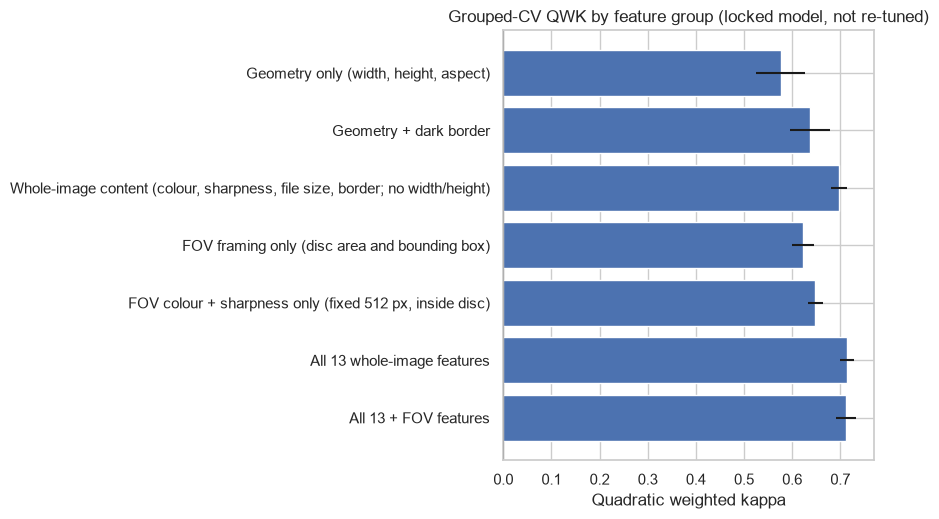

In [62]:
plt.figure(figsize=(9, 0.55 * len(ablation) + 1.5))
plt.barh(ablation["feature group"][::-1], ablation["cv_qwk_mean"][::-1], xerr=ablation["cv_qwk_std"][::-1].fillna(0), color="#4C72B0")
plt.axvline(0, color="black", lw=0.8)
plt.title("Grouped-CV QWK by feature group (locked model, not re-tuned)")
plt.xlabel("Quadratic weighted kappa")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_metadata_shortcut_ablation.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation (quick check on the saved CSV before this notebook was rebuilt; ungrouped 5-fold CV, same locked model, so the notebook's grouped numbers may differ by about ±0.02).** Geometry only (width, height, aspect ratio) reaches QWK about 0.57; aspect ratio alone about 0.55; geometry plus dark-border fraction about 0.63; the ten content-like whole-image statistics without width and height about 0.70; all 13 about 0.70. The two `fov_*` groups are new: their numbers appear in the table above.

**Interpretation.**

1. **Three numbers that describe only how the image is framed already give QWK ≈ 0.57**, roughly 80% of what all 13 features achieve. This is the cleanest evidence of a source-level shortcut, because geometry says nothing about the retina.

2. The "content" group reaches 0.70 *without* width and height, but file size and native sharpness encode the pixel count, and colour statistics are diluted by the border. So this group cannot be read as "the model sees disease-related colour or sharpness".

3. The `fov_*` colour/sharpness group is the informative one. 

Two cases:

- (a) if its QWK is **much lower** than the whole-image content group, most of that group's signal was resolution and border leaking in
- (b) if it is **similar**, the colour and sharpness statistics inside the disc are themselves tied to the grade, either through camera/processing differences between sources or through real disease appearance (more lesions change colour spread). 

Metadata cannot distinguish these two; only the within-source test below and image-level work can.

# 6  Resolution lookup baseline and within-source test

Two last checks that isolate *source* from *content*.

**6.1 Lookup table.** Predict, for each validation image, the most common training grade at its exact resolution. There is no learning; it only uses what Section 5 of notebook 01 showed.

**6.2 Within-source.** Hold resolution fixed. For each resolution with enough images of at least three grades, test whether the *content-like* measurements still predict the grade. If resolution is the only thing the metadata knows, the score inside a source should fall to chance. This is exploratory: it pools train and validation (the sets are small) and uses a small fixed model with no tuning.

In [66]:
lookup_pred = resolution_lookup_predictions(train_data, val_data)
lookup_metrics = shortcut_metrics(y_val, lookup_pred)
print("Resolution-only lookup, validation:", {k: round(v, 3) for k, v in lookup_metrics.items()})
print(f"Fraction of the locked model's validation QWK reached by the lookup: {lookup_metrics['qwk'] / validation_metrics['qwk']:.0%}")

Resolution-only lookup, validation: {'qwk': 0.594, 'macro_f1': 0.337, 'balanced_accuracy': 0.364, 'accuracy': 0.701}
Fraction of the locked model's validation QWK reached by the lookup: 87%


In [67]:
within_features = FOV_COLOUR_SHARPNESS_FEATURES if FOV_AVAILABLE else [f for f in WHOLE_IMAGE_FEATURES if f not in {"file_size_bytes", "blur_laplacian_variance"}]
print("Within-source features:", within_features)

def small_model():
    return HistGradientBoostingClassifier(max_leaf_nodes=7, learning_rate=0.05, max_iter=100, min_samples_leaf=10,
                                          l2_regularization=1.0, class_weight="balanced", early_stopping=False, random_state=SEED)

rows = []
for resolution, subset in model_data.groupby("resolution"):
    grade_counts = subset["diagnosis"].value_counts()
    kept_grades = grade_counts[grade_counts >= 10].index
    subset = subset[subset["diagnosis"].isin(kept_grades)]
    if len(subset) < 200 or len(kept_grades) < 3:
        continue
    y_sub = subset["diagnosis"].astype(int).to_numpy()
    predictions = cross_val_predict(
        make_shortcut_pipeline(small_model(), within_features), subset[within_features].astype(float), y_sub,
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    )
    rows.append({
        "resolution": resolution, "images": len(subset), "grades kept": sorted(int(g) for g in kept_grades),
        "QWK": cohen_kappa_score(y_sub, predictions, weights="quadratic"),
        "balanced accuracy": balanced_accuracy_score(y_sub, predictions),
        "accuracy": float((predictions == y_sub).mean()),
        "majority-class accuracy": float(pd.Series(y_sub).value_counts(normalize=True).max()),
    })
within_source = pd.DataFrame(rows).sort_values("images", ascending=False)
within_source.to_csv(REPORT_DIR / "aptos_metadata_within_source.csv", index=False)
display(within_source.round(3))

Within-source features: ['fov_brightness_mean', 'fov_red_mean', 'fov_green_mean', 'fov_blue_mean', 'fov_red_std', 'fov_green_std', 'fov_blue_std', 'fov_blur_laplacian_variance']


,resolution,images,grades kept,QWK,balanced accuracy,accuracy,majority-class accuracy
0,1050x1050,822,"[0, 1, 2]",0.232,0.446,0.897,0.940
1,2416x1736,500,"[0, 1, 2, 3, 4]",0.085,0.267,0.350,0.402
2,2588x1958,460,"[0, 1, 2, 3, 4]",0.448,0.387,0.539,0.446
3,3216x2136,309,"[1, 2, 3, 4]",-0.050,0.226,0.566,0.751


**Observation.** 

The lookup table reaches validation QWK 0.594, accuracy 0.701 and balanced accuracy 0.364, about 86% of the locked 13-feature model's QWK (0.692) with no learning at all. 

In a quick check on the saved CSV using the ten whole-image content-like statistics (no width or height), the within-source test gave: inside 2416 × 1736 (500 images) QWK about 0.085 and accuracy 0.35, **below** the 0.40 of always predicting the majority grade; inside 2588 × 1958 (460 images) QWK about 0.44 and accuracy 0.54 against 0.45 for the majority guess. The table above uses the `fov_*` colour/sharpness features instead, so its values will differ; for every row compare `accuracy` with `majority-class accuracy`.

A source where accuracy does not beat the majority column has no usable content signal.

**Interpretation.**
* A resolution lookup table gets most of the way to a boosted-tree model, so **the shortcut is mostly the source**, not subtle statistics.

* Inside 2416 × 1736 the metadata knows almost nothing about the grade, which is what we want to see in a source without a source-level clue.

* Inside 2588 × 1958 there is residual signal, matching the blue-channel relation seen in notebook 01. It may reflect sub-sources with different cameras or processing at the same resolution, or real disease appearance. This is the first place to look at images.



In [68]:
summary = {
    "split_manifest": rel(SPLIT_CSV),
    "n_train": int(len(train_data)), "n_validation": int(len(val_data)),
    "locked_model": best_model_name,
    "cv": {"qwk_mean": float(best_cv_row["qwk_mean"]), "qwk_std": float(best_cv_row["qwk_std"]),
        "best_dummy_qwk": float(baseline_cv["qwk_mean"].max())},
    "validation": {k: float(v) for k, v in validation_metrics.items()},
    "validation_baselines": {name: {k: float(v) for k, v in values.items()} for name, values in validation_baselines.items()},
    "validation_label_shuffle_p": {"qwk": float(qwk_p), "balanced_accuracy": float(balanced_p), "shuffles": 1000},
    "resolution_lookup_validation": {k: float(v) for k, v in lookup_metrics.items()},
    "ablation_cv_qwk": {row["feature group"]: float(row["cv_qwk_mean"]) for _, row in ablation.iterrows()},
    "duplicate_groups_spanning_train_and_validation": int(len(cross_split_groups)),
    "test_partition_used": False,
}
(REPORT_DIR / "aptos_metadata_shortcut_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Saved", rel(REPORT_DIR / "aptos_metadata_shortcut_summary.json"))
print(json.dumps(summary["cv"] | {"validation_qwk": summary["validation"]["qwk"], "lookup_qwk": summary["resolution_lookup_validation"]["qwk"]}, indent=2))

Saved reports/aptos_metadata_shortcut_summary.json
{
  "qwk_mean": 0.7133573684745553,
  "qwk_std": 0.014427704877648863,
  "best_dummy_qwk": 0.014516115994140221,
  "validation_qwk": 0.6855971308224305,
  "lookup_qwk": 0.5941312443816618
}


# 7 Conclusion, limitations, and next steps for the CNN phase

**Scope.** This is a metadata-only analysis of the APTOS development split (2,438 training and 525 validation images). The sealed test partition was not loaded or used.

## Findings

The strongest metadata-only model in the notebook's current output achieved **grouped 5-fold CV QWK 0.713 ± 0.014** and **validation QWK 0.686**. The validation majority-class baseline had QWK 0.000; the stratified-random baseline was about -0.022. Thus, image-level measurements contain substantial information about the recorded DR grade, even without retinal structure.

The evidence does **not** show that resolution alone explains the result:

| Feature set / probe | CV QWK | Validation QWK |
|---|---:|---:|
| Geometry only (width, height, aspect ratio) | 0.576 | 0.543 |
| Resolution lookup table | — | 0.594 |
| Whole-image measurements excluding width and height | 0.697 | 0.690 |
| FOV colour and sharpness measurements | 0.648 | 0.627 |
| All 13 whole-image measurements | 0.713 | 0.686 |

This points to several predictive acquisition or image-statistic cues, not just image dimensions. Feature importance and ablation results are associations; they do not establish which camera, clinic, or image property caused the signal.

The within-resolution results also show that resolution does not account for everything: the 2588 × 1958 group (460 images) had QWK 0.448, while the 2416 × 1736 group (500 images) had QWK 0.085. These are exploratory subgroup results, not proof of a residual source effect. Resolution groups are not verified camera or clinic labels, and their grade mixes and sample sizes differ.

**Verdict:** this download contains a meaningful metadata shortcut risk. A CNN trained and evaluated on a random image split could use acquisition or other non-pathology cues. CNN performance must be evaluated with source-sensitive and external tests before making claims about disease learning or generalisation.



## What to do next

1. **Re-run and reconcile the artifacts first.** Restart the kernel and run this notebook top to bottom. Its current output reports CV QWK 0.713 ± 0.014 and validation QWK 0.686; a saved validation report instead records QWK 0.692 for a different model. Regenerate reports and ensure the conclusion, notebook output, and saved summaries all refer to the same run and model.

2. **Measure shortcut signal after the actual CNN preprocessing.** Apply one fixed preprocessing pipeline to every image, then repeat the metadata probe on the resulting images. Report which features remain available after resizing and cropping; do not assume preprocessing removes source cues.

3. **Evaluate the CNN beyond the full split.** Report QWK, macro-F1, balanced accuracy, grade support, and per-grade results on the full validation set, separately by resolution, and on the two mixed-grade resolution groups (2588 × 1958 and 2416 × 1736). Treat the matched-group comparison as a diagnostic, not a causal estimate of shortcut use.

4. **Test source-balanced training as a sensitivity analysis.** Compare it with the plain baseline under the same split and evaluation protocol. Report the grade mix and sample counts by group; balancing is not guaranteed to improve generalisation.

5. **Make external evaluation the main generalisation test.** Once a compatible dataset and its terms are verified, evaluate across datasets or acquisition sources. A random split of this one download cannot establish cross-site or cross-camera performance.

6. **Investigate provenance.** Ask the clinical collaborator which clinics or cameras correspond to the observed image characteristics, and inspect images at both ends of the blue-channel range within 2588 × 1958. Do not equate resolution with a confirmed source until that mapping is established.

7. **Document split verification.** The split-creation script is designed to group duplicates across its three input partitions before assigning train, validation, and test. Preserve evidence that the frozen manifest was created that way and that groups do not cross any partition boundary; keep the test sealed until final evaluation.



## Limitations

- **No patient identifiers:** these are image-level, not patient-level, splits. Images from the same person could cross partitions.

- **Near-duplicate checks are incomplete:** hash/SSIM grouping catches some near-identical images, not all crops, rotations, recolourings, or images of the same patient. The notebook found no detected group spanning train and validation, which does not rule out patient leakage.

- **One dataset and one frozen split:** results apply to this APTOS download and protocol only. There is no external validation here.

- **Source is unknown:** resolution and image statistics are proxies, not verified clinic, camera, or acquisition-site identifiers. The within-resolution signal cannot be attributed to a particular source.

- **Subgroup estimates are limited:** only the 2588 × 1958 and 2416 × 1736 groups contain all five grades in the reported table. Their grade distributions differ; other groups omit grades. Subgroup QWKs are therefore not directly comparable, and small grade counts add uncertainty.

- **Class imbalance and weak minority-grade performance:** validation supports were 270, 51, 138, 26, and 40 images for grades 0–4. In the notebook's current output, recall was low for grades 1, 3, and 4; aggregate QWK should not hide this.

- **Model-selection optimism:** the reported best CV score is the maximum among 12 candidate configurations evaluated on the same folds, so it is a selection score, not an unbiased final performance estimate.

- **Indirect, engineered measurements:** metadata and FOV statistics are not retinal-lesion measurements. Their permutation importance is not causal, and the FOV measurements are not a substitute for testing the exact CNN preprocessing pipeline.

- **Reproducibility and provenance remain open:** the saved validation metrics currently disagree, and the exact source, licence terms, and download details for the pre-split upload still need confirmation.

**Bottom line:** treat the result as a warning that metadata can predict labels in this dataset—not as evidence that a CNN has learned pathology. The next decisive steps are to reconcile the run outputs, repeat the probe after fixed preprocessing, evaluate per source/resolution, and test on external data.